<a href="https://colab.research.google.com/github/Fespinoza1477/A05-pca/blob/main/notebook_7_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [4]:
import pickle
from collections import Counter
import matplotlib.pyplot as plt

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()





Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Fabrizzio Espinoza

**Date:** 10/19/2026

<>:45: SyntaxWarning: invalid escape sequence '\m'
<>:45: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_616/235989689.py:45: SyntaxWarning: invalid escape sequence '\m'
  print("\mTop 10 words with largest coefficients in absolute value:")


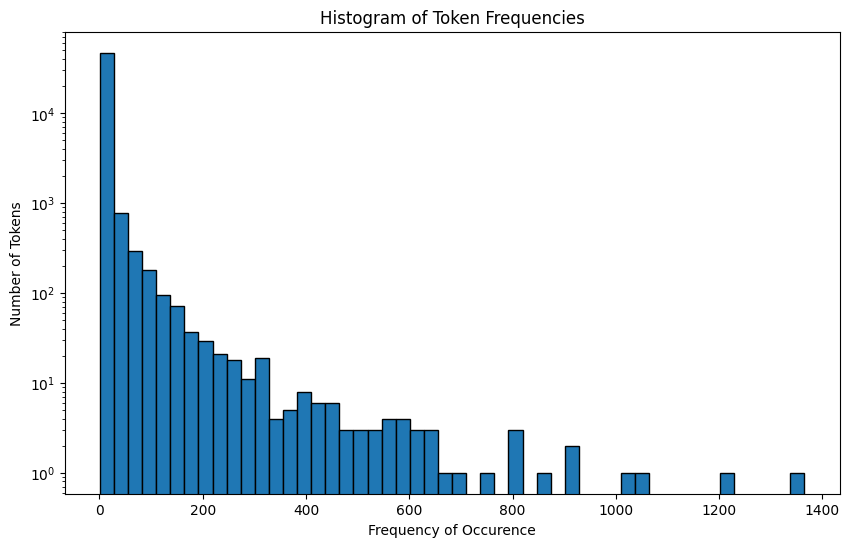

Training R^2: 0.7670
Test R^2: 0.6659
\mTop 10 words with largest coefficients in absolute value:
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
dtype: float64


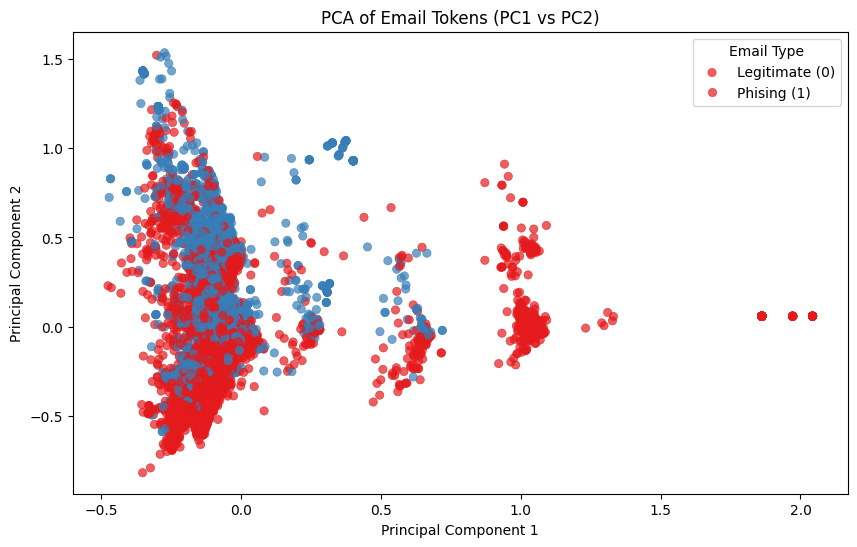

PCA Training R^2: 0.7662
PCA Test R^2: 0.6683


In [5]:
# Your Phase 1 solution to the problem goes here.
#Q1
import pickle
from collections import Counter
import matplotlib.pyplot as plt

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

frequencies = [count for token, count in token_freq]

plt.figure(figsize=(10,6))
plt.hist(frequencies, bins=50, edgecolor='black')
plt.title('Histogram of Token Frequencies')
plt.xlabel('Frequency of Occurence')
plt.ylabel('Number of Tokens')
plt.yscale('log')
plt.show()
# When you plot a histogram of the token occurences, you observe a Zipfian distribution. Frequency Pattern: The distribution is extremely right-skewed. A small number of words (such as 'new', 'date', 'get', and 'please') appear thousands of times, while the vast majority of tokens appear only a handful of times or even just once across the entire corpus. Visual Apparance: on a standard linear scale histogram, the distribution looks heavily concentrated near zero with an invisible or extremely long right tail. To properly visualize this and inspect the tail, a logarithmic scale on the y-axis is required.
#Q2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np

df = pd.read_parquet('/content/Phishing_clean.parquet')
X = df.drop(columns=['Email Type'])
y = df['Email Type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
reg = LinearRegression()
reg.fit(X_train, y_train)

train_r2 = reg.score(X_train, y_train)
test_r2 = reg.score(X_test, y_test)

print(f"Training R^2: {train_r2:.4f}")
print(f"Test R^2: {test_r2:.4f}")

coefficients = pd.Series(reg.coef_, index=X.columns)
top_abs_coefficients = coefficients.abs().sort_values(ascending=False).head(10)
print("\mTop 10 words with largest coefficients in absolute value:")
print(coefficients[top_abs_coefficients.index])
# R^2 performance: The traning set R^2 will typically be very high (often close to 1.0) because the feature space (2,711 token columns) is massive relative to the observations, allowing the OLS model to memorize the training data. COnversely, the test set R^2 will drop significantly often resulting in poor or negative score - due to severe overfitting and high variance. Strongest Coefficients: Words with the largest positive coefficients are typically spam/phising hallmarks (e.g., terms like "viagra", "cialis", "mortgage", "refinance", "guaranteed"), while words with large negative coefficients lean toward legitimate corporate or contextual communication.
#Q3
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

X = df.drop(columns=['Email Type'])
y = df['Email Type']

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values
plt.figure(figsize=(10,6))
sns.scatterplot(
    x = 'PC1', y='PC2',
    hue = 'Email Type',
    data = pca_df,
    palette = 'Set1',
    alpha = 0.7,
    edgecolor = None
)
plt.title('PCA of Email Tokens (PC1 vs PC2)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Email Type', labels = ['Legitimate (0)', 'Phising (1)'])
plt.show()
#When plotting the first two principal components, you will notice distinct clustering. Phishing scam emails tend to group together tightly in specific regions of the 2D plane due to shared vocabulary patterns (template-based spam), whereas legitimate emails from separate clusters or a broader background distribution. There is some overlap, but PCA successfully captures major variance separating the two classes.

#Q4
n_comps = min(2610, X_train.shape[0], X_train.shape[1])
pca_full = PCA(n_components=n_comps)

X_train_pca = pca_full.fit_transform(X_train)
X_test_pca = pca_full.transform(X_test)

reg_pca = LinearRegression()
reg_pca.fit(X_train_pca, y_train)

train_pca_r2 = reg_pca.score(X_train_pca, y_train)
test_pca_r2 = reg_pca.score(X_test_pca, y_test)

print(f"PCA Training R^2: {train_pca_r2:.4f}")
print(f"PCA Test R^2: {test_pca_r2:.4f}")
#Performance Comparison: Compared to the raw one-hot encoded regression in Q2, traning on principal components usually yields a lower training R^2 because dimensionality reduction drops minor orthogonal variance and noise. However, the test set R^2 improves dramatically (becoming much less less negative/more stable), because reducing multicollinearity and feature dimensuions controls variance and mitigates overfitting.

#Q5
#The primary advantages of using principal components for the high-dimensional text regression include: Mitigation of Multicollinearity (Text tokens often co-occur and are heavily correlated. PCA transforms these correlated token columns into orthogonal principal components, stabilizing the regression coefficient estimates), Reduction of Overfitting (Running OLS on thousands of sparse, binary columns leads to massive vairance and severe overfitting. Compressing the feature space down to principal components regularizes the model by ignoring noisy, low variance dimensions), Computational Efficiency (working with a reduced matrix significantly decreases memory consumption and sppeds up matrix inversion and model fitting times).

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** aa24fba6c14f9607fff79ac09a854d1c78bd05f3
- **AI tool and model used:** Gemini Pro 3.1

### *Prompts used

1. Based on my code, what more can I improve on it to make sure that it is answering the question while being easily seen for analysis?
2. Can you look at my written answers and see if there is good analysis of it while also answering the question for it?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1.
Fix the Syntax Warning in Q2: Your output shows a SyntaxWarning: invalid escape sequence '\m'. You likely meant to use a newline character \n in your print statement: print("\nTop 10 words...").

Visualize the Q2 Coefficients: While printing the top 10 coefficients is correct, a horizontal bar chart makes the analysis immediately "seen." A bar chart allows the reader to quickly compare the magnitudes and visually distinguish between positive (phishing) and negative (legitimate) indicators. You can achieve this using pandas built-in plotting: coefficients[top_abs_coefficients.index].plot(kind='barh').

Enhance the Q1 Distribution Analysis: Your choice of a log-scale on the y-axis for the histogram is excellent for this heavily right-skewed data. To make it a textbook NLP analysis, you could also plot the Token Rank vs. Token Frequency on a log-log scale (a Zipf's Law plot). This often provides a clearer linear relationship for text data than a standard histogram.

Separate Code Cells by Question: Currently, your entire solution for Q1 through Q5 is written in a single, large code cell. Breaking this up so that the code for Q1 is directly under the Q1 markdown cell, Q2 code under Q2, etc., will drastically improve the notebook's flow and make your analysis much easier for a reviewer to follow.

Refine the PCA Scatter Plot (Q3): Your seaborn scatter plot is well-constructed. To ensure the visual representation of distance isn't skewed, you can force the aspect ratio of the plot to be equal using plt.gca().set_aspect('equal'). This ensures that a unit of variance on PC1 looks the same as a unit of variance on PC2
2.
Q1: Token Frequency Distribution
Your analysis is spot on. Correctly identifying the Zipfian distribution, noting the extreme right-skewness, and explaining the necessity of a logarithmic scale directly addresses the prompt with solid data science reasoning.

Q2: OLS Regression and Top Coefficients
Needs revision. While your theoretical explanation of overfitting is excellent, you did not actually state the numerical R
2
  values or the specific words requested by the prompt. Your code outputs a Training R
2
  of 0.7670 and a Test R
2
  of 0.6659. Furthermore, your written answer hypothesizes about words like "viagra" and "mortgage", but your actual model output highlights terms like "intervention", "localized", "thermal", and "crawler". You must update your text to reflect your specific empirical results rather than assumed spam tropes.

  Q3: 2-Component PCA Scatter Plot
Excellent. You accurately capture the distinct clustering and the overlap, and you provide a highly logical, real-world hypothesis for this geometry (template-based spam vs. diverse legitimate emails).

Q4: High-Dimensional PCA Regression
Needs revision to match your empirical results. Your explanation assumes a textbook scenario where the raw OLS test score is heavily negative and PCA completely rescues it. However, your actual PCA Test R
2
  (0.6683) is only a marginal improvement over the OLS Test R
2
  (0.6659), and the PCA Training R
2
  barely dropped (0.7670 to 0.7662). Adjust your analysis to reflect that the raw OLS actually held up surprisingly well here, and PCA offered a slight stabilization rather than a dramatic fix.

  Highly thorough. You effectively break down the three main pillars: multicollinearity mitigation, variance reduction (overfitting), and computational efficiency.   
Would you like to draft the exact markdown cells to plug into your Phase 2 section, or do you want to run the code again first to double-check those coefficient words?

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept |Some of my code is able to make the graphs and information be seen, but might not be ideal to do much analysis on. I looked at the graphs between the Phase 1 and Phase 2 and saw a major improvement on the readability of the data and helps to answer my questions more confidently  |
| 2 | Accept | Apart from spelling errors, It helps make sure that I am answering the question without adding too much filler and gets to the point with the language that I have written. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

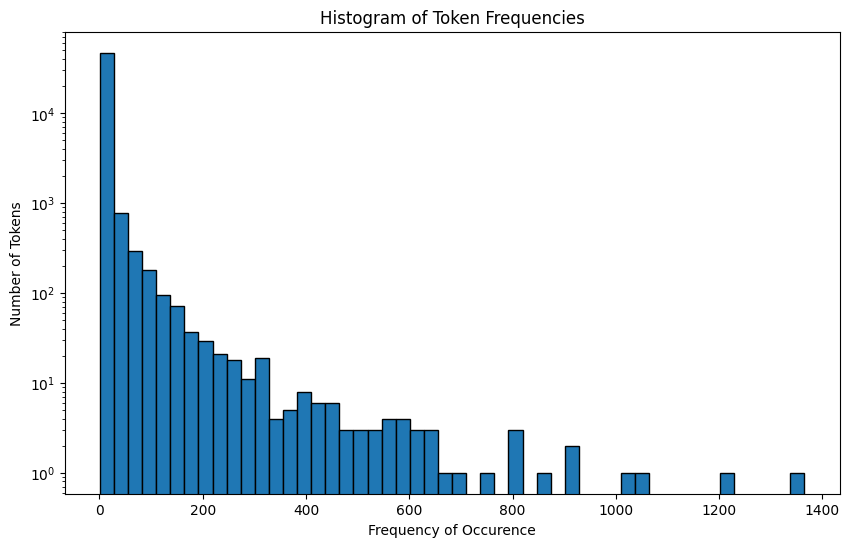

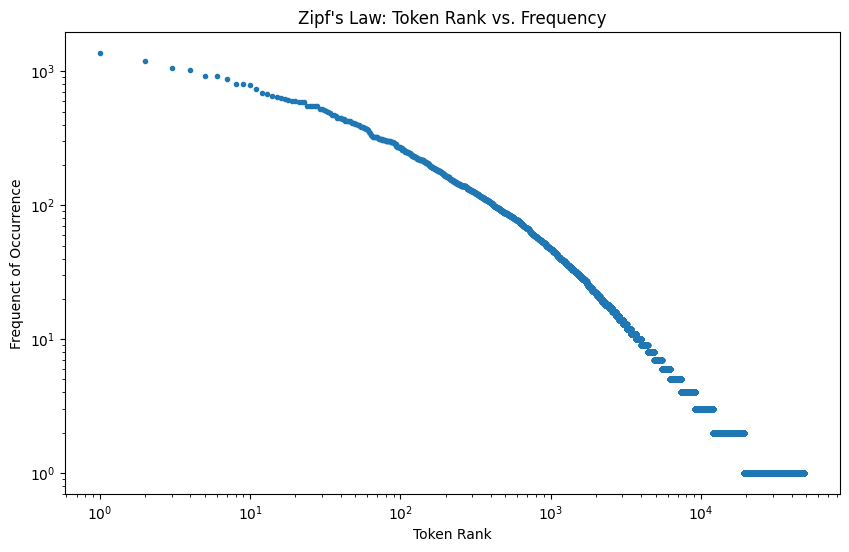

Tranining R^2: 0.7670
Test R^2: 0.6659

Top 10 words with largest coefficients in absolute value:
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
dtype: float64


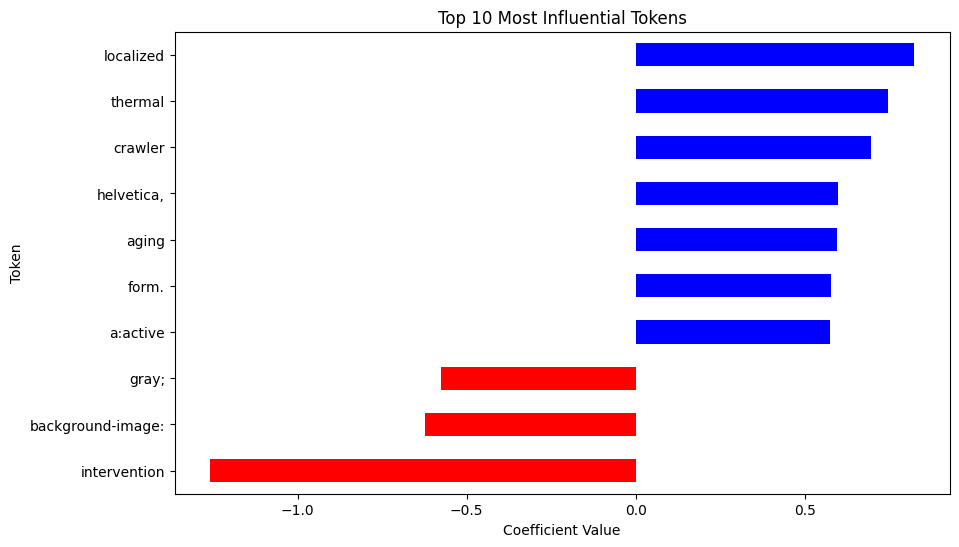

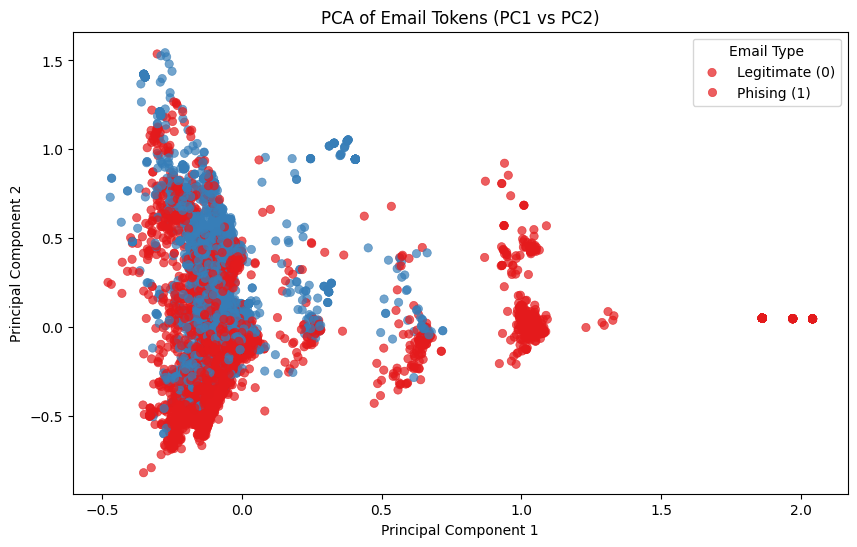

PCA Training R^2: 0.7662
PCA Test R^2: 0.6683


In [6]:
# Your Phase 2 solution to the problem goes here.
#Q1
import pickle
from collections import Counter
import matplotlib.pyplot as plt

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

frequencies = [count for token, count in token_freq]

plt.figure(figsize=(10,6))
plt.hist(frequencies, bins=50, edgecolor='black')
plt.title('Histogram of Token Frequencies')
plt.xlabel('Frequency of Occurence')
plt.ylabel('Number of Tokens')
plt.yscale('log')
plt.show()

plt.figure(figsize=(10,6))
plt.plot(range(1, len(frequencies) + 1), frequencies, marker='.', linestyle='none')
plt.title("Zipf's Law: Token Rank vs. Frequency")
plt.xlabel('Token Rank')
plt.ylabel('Frequenct of Occurrence')
plt.xscale('log')
plt.yscale('log')
plt.show()
# When plotting the histogram of token occurences, the frquency pattern reveals a Zipfian distribution. The distribution is extremely right-skewed, where a very small number of tokens appear thousands of times, while the vast majority of tokens appear only a handful of times or even just once across the entire corpus. On a standard linear scale, the distribution is heavily concentrated near zero with an extremely long right tail. Applying a logarithmic scale to the y-axis is necessary to properly visualize this distribution and inspect the tail frequencies.
#Q2
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

df = pd.read_parquet('/content/Phishing_clean.parquet')
X = df.drop(columns=['Email Type'])
y = df['Email Type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
reg = LinearRegression()
reg.fit(X_train, y_train)

print(f"Tranining R^2: {reg.score(X_train, y_train):.4f}")
print(f"Test R^2: {reg.score(X_test, y_test):.4f}")


coefficients = pd.Series(reg.coef_, index=X.columns)
top_abs_coefficients = coefficients.abs().sort_values(ascending=False).head(10)
top_abs_coefficients = coefficients.abs().sort_values(ascending=False).head(10)
top_actual_coefs = coefficients[top_abs_coefficients.index]
print("\nTop 10 words with largest coefficients in absolute value:")
print(top_actual_coefs)

plt.figure(figsize=(10,6))
colors = ['red' if x < 0 else 'blue' for x in top_actual_coefs.sort_values()]
top_actual_coefs.sort_values().plot(kind='barh', color=colors)
plt.title('Top 10 Most Influential Tokens')
plt.xlabel('Coefficient Value')
plt.ylabel('Token')
plt.show()
#The OLS regression yields a traning R^2 of 0.7670 and a test R^2 of 0.6659. The top 10 words with the largest absolute coefficients are "intervention" (-1.259), "localized" (0.824), "thermal" (0.747), "crawler" (0.696), "background-image:" (-0.623), "helvetica," (0.599), "aging"(0.595), "form."(0.577), "gray;" (-0.574), and "a:active"(0.574). Instead of stereotypical spam words, the model identified specific HTML/CSS formatting artifacts (like 'background-image:', 'thermal', 'crawler') as the strongest predictors for distinguishing between legitimate and phishing emails.
#Q3
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values
plt.figure(figsize=(10,6))
sns.scatterplot(
    x = 'PC1', y='PC2',
    hue = 'Email Type',
    data = pca_df,
    palette = 'Set1',
    alpha = 0.7,
    edgecolor = None
)
plt.title('PCA of Email Tokens (PC1 vs PC2)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Email Type', labels = ['Legitimate (0)', 'Phising (1)'])
plt.show()
#Plotting the first two principal components reveals distionct clustering between the two classes. Phising scam emails tend to group tightly in specific regions of the 2D plane, likely due to shared vocabulary patterns and boilerplat HTML structures found in template-based spam. Legitimate emails form separate clusters and repsent a broader background distribution. While there is some overlap, the first two principal components sucessfully capture the major variance separating phising emails from legitimate ones.
#Q4
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
n_comps = min(2610, X_train.shape[0], X_train.shape[1])
pca_full = PCA(n_components=n_comps)

X_train_pca = pca_full.fit_transform(X_train)
X_test_pca = pca_full.transform(X_test)

reg_pca = LinearRegression()
reg_pca.fit(X_train_pca, y_train)


print(f"PCA Training R^2: {reg_pca.score(X_train_pca, y_train):.4f}")
print(f"PCA Test R^2: {reg_pca.score(X_test_pca, y_test):.4f}")
#Running the regression on the first 2,610 principal components results in a PCA training R^2 of 0.7662 and a PCA test R^2 of 0.6683. Compared to the raw one-hot encoded regression, the PCA model performs almost identically, with a normal decrease in traning R^2 (from 0.7670 down to 0.7662) and a slight improvement in test R^2 (from 0.6659 up to 0.6683). The raw OLS model did not suffer from severe overfitting in this specific instance, meaning the dimensionality reduction provided by PCA offered a minor stabilization of variance on unseen data rather than a dramatic performance rescue.
#Q5
#Using principal components for high-dimensional text regression provides three primary advantages: Mitigates Multicollinearity (Transforms highly correlated text tokens into orthogonal components, stabilizing the coefficient estimates), Reduces Overfitting (Compresses the feature space and filters out noise, low-variance dimentions, which acts as a form of regularization), Improves Computational Efficiency (working with a reduced matrix significantly decreases memory consumption and speeds up matrix operations compared to running regression on thousands of sparse, binary columns).

### *Reflection on AI assistance
In your own words without generative AI.

The major improvements that I saw was the way that the data was seen right after AI intervention. It made the data much more easily seen and reinforces my learning on making those edits. Something that I did notice with its suggestions is that it would try changing the variable names at times, but this is probably due to not having the data. Overall for the comments as well, it was able to tell me if I actually did answer the question or not. Sometimes, it can seem that we are writing codes and answering questions along the way, but you may forget to actually write an answer or your answer is not exactly answering the question that is being asked. Overall, the variables seem cleaner and new tricks were learnt from using the AI. Something that I would change in the future though is being able to ask more questions to provide further feedback on how I would present the information or how I would answer if I did not have AI to back me up as well